<a href="https://colab.research.google.com/github/192572037simats-tech/DSA0406---FODS/blob/main/EXP_7-20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

7\. Question: Using Pandas DataFrame operations, how would you find the following information  
from the order_data DataFrame:  
1\. The total number of orders made by each customer.  
2\. The average order quantity for each product.  
3\. The earliest and latest order dates in the dataset.

In [ ]:
import pandas as pd

order_data = pd.DataFrame({
    "customer_id": ["C101", "C102", "C101", "C103", "C102", "C101"],
    "order_date": ["2026-09-02", "2026-09-05", "2026-09-10",
                   "2026-09-15", "2026-09-20", "2026-09-28"],
    "product_name": ["Laptop", "Mouse", "Keyboard", "Mouse", "Laptop", "Mouse"],
    "order_quantity": [1, 3, 2, 1, 2, 4]
})
order_data["order_date"] = pd.to_datetime(order_data["order_date"])
print("Orders per customer:")
print(order_data.groupby("customer_id").size().rename("total_orders"))
print("\nAverage quantity per product:")
print(order_data.groupby("product_name")["order_quantity"].mean().round(2))
print("\nEarliest order:", order_data["order_date"].min().date())
print("Latest order:", order_data["order_date"].max().date())


Orders per customer:
customer_id
C101    3
C102    2
C103    1
Name: total_orders, dtype: int64

Average quantity per product:
product_name
Keyboard    2.00
Laptop      1.50
Mouse       2.67
Name: order_quantity, dtype: float64

Earliest order: 2026-09-02
Latest order: 2026-09-28


8\. Question: How would you find the top 5 products that have been sold the most in the past month?

In [ ]:
import pandas as pd

analysis_date = pd.Timestamp("2026-10-01")
month_end = analysis_date.replace(day=1)
month_start = month_end - pd.DateOffset(months=1)
sales_data = pd.DataFrame({
    "order_date": ["2026-09-02", "2026-09-04", "2026-09-07", "2026-09-09",
                   "2026-09-12", "2026-09-15", "2026-09-18", "2026-09-25",
                   "2026-08-30", "2026-10-01"],
    "product_name": ["Mouse", "Keyboard", "Laptop", "Monitor", "Headphones",
                     "Webcam", "Mouse", "Keyboard", "Webcam", "Laptop"],
    "quantity": [40, 25, 10, 20, 30, 15, 35, 20, 100, 200]
})
sales_data["order_date"] = pd.to_datetime(sales_data["order_date"])
last_month = sales_data[
    (sales_data["order_date"] >= month_start) &
    (sales_data["order_date"] < month_end)
]
top_five = (last_month.groupby("product_name")["quantity"].sum()
            .sort_values(ascending=False).head(5))
print("Period:", month_start.date(), "to", (month_end - pd.Timedelta(days=1)).date())
print("Top five products by units sold:")
print(top_five.rename("units_sold"))


Period: 2026-09-01 to 2026-09-30
Top five products by units sold:
product_name
Mouse         75
Keyboard      45
Headphones    30
Monitor       20
Webcam        15
Name: units_sold, dtype: int64


9\. Question: Using Pandas DataFrame operations, how would you find the following information  
from the property_data DataFrame:  
1\. The average listing price of properties in each location.  
2\. The number of properties with more than four bedrooms.  
3\. The property with the largest area.

In [ ]:
import pandas as pd

property_data = pd.DataFrame({
    "property_id": ["P101", "P102", "P103", "P104", "P105", "P106"],
    "location": ["Chennai", "Coimbatore", "Chennai", "Madurai", "Coimbatore", "Madurai"],
    "bedrooms": [3, 5, 6, 4, 2, 5],
    "area_sq_ft": [1500, 2400, 3200, 1900, 1200, 2600],
    "listing_price": [6500000, 7500000, 12500000, 5500000, 4000000, 8500000]
})
print("Average listing price by location (INR):")
print(property_data.groupby("location")["listing_price"].mean().round(2))
print("\nProperties with more than four bedrooms:",
      int((property_data["bedrooms"] > 4).sum()))
largest = property_data[property_data["area_sq_ft"] == property_data["area_sq_ft"].max()]
print("\nProperty/properties with largest area:")
print(largest.to_string(index=False))


Average listing price by location (INR):
location
Chennai       9500000.0
Coimbatore    5750000.0
Madurai       7000000.0
Name: listing_price, dtype: float64

Properties with more than four bedrooms: 3

Property/properties with largest area:
property_id location  bedrooms  area_sq_ft  listing_price
       P103  Chennai         6        3200       12500000


10\. Question:  
1\. How would you develop a Python program to create a line plot of the monthly sales data?  
2: How would you develop a Python program to create a bar plot of the monthly sales data?

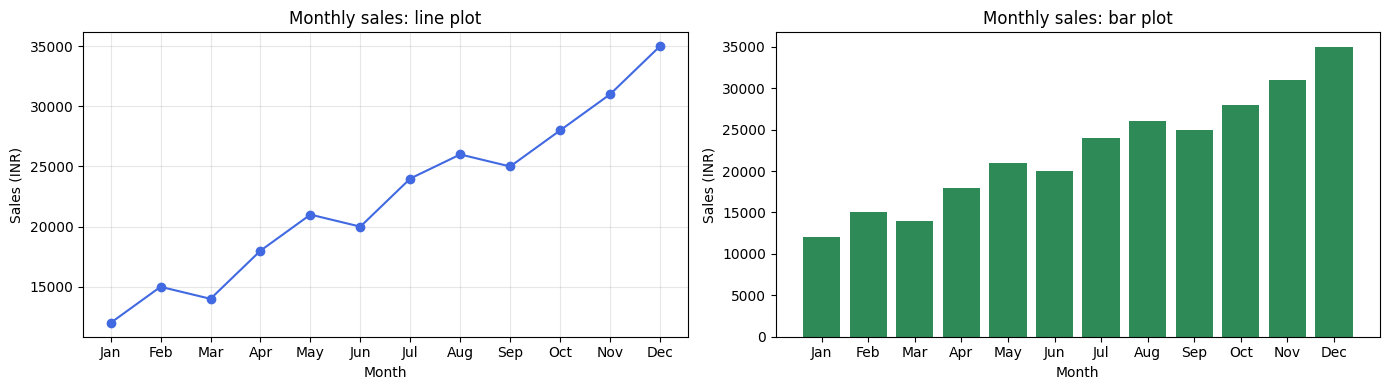

In [ ]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sales = [12000, 15000, 14000, 18000, 21000, 20000,
         24000, 26000, 25000, 28000, 31000, 35000]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(months, sales, marker="o", color="royalblue")
axes[0].set_title("Monthly sales: line plot")
axes[0].grid(alpha=0.3)
axes[1].bar(months, sales, color="seagreen")
axes[1].set_title("Monthly sales: bar plot")
for ax in axes:
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales (INR)")
plt.tight_layout()
plt.show()


11\. Question:  
1\. Write code to create a simple line plot in Python using Matplotlib to predict sales happened in a  
month?  
2\. Write code to create a scatter plot in Python using Matplotlib to predict sales happened in a  
month?  
3\. Develop a Python program to create a bar plot of the monthly sales data.plot of the monthly sales data.

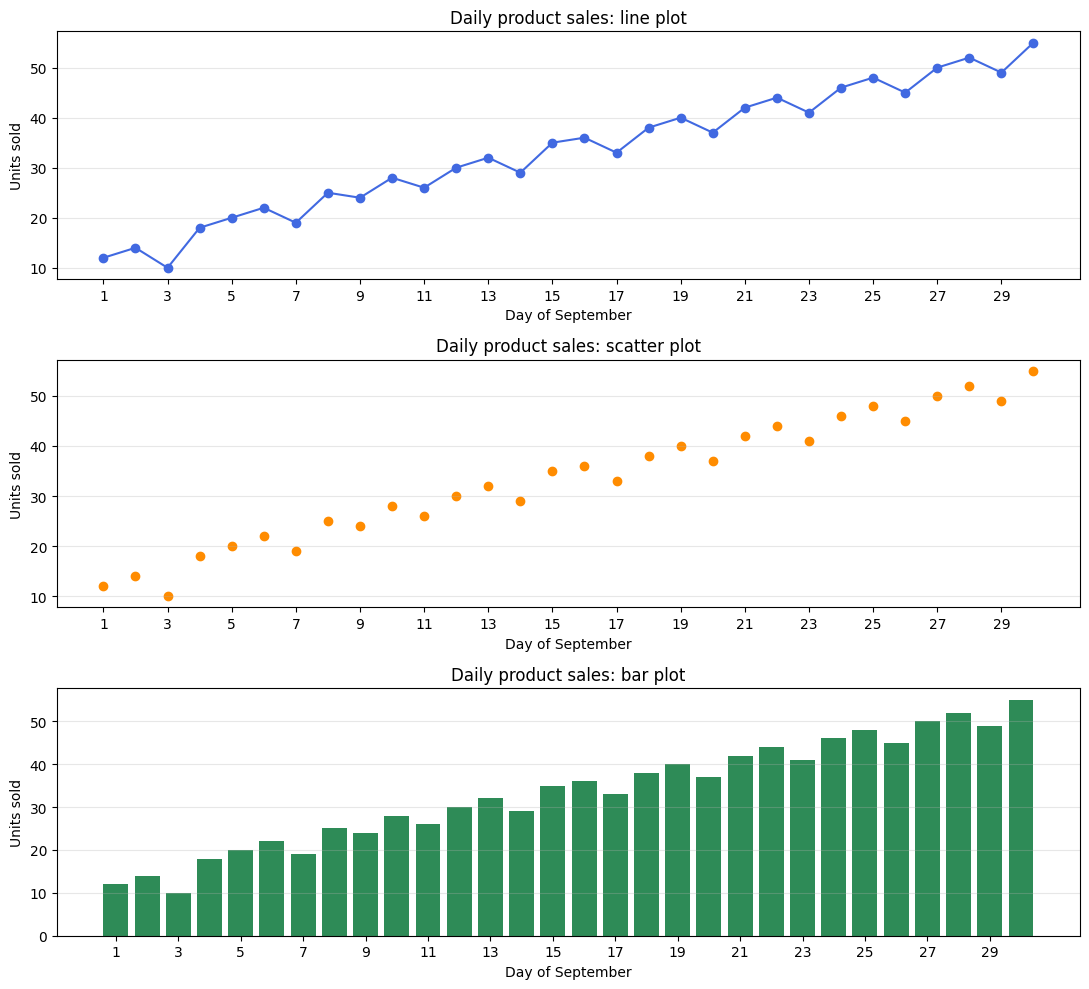

Total units sold in the month: 1000


In [ ]:
import matplotlib.pyplot as plt

days = list(range(1, 31))
sales = [12, 14, 10, 18, 20, 22, 19, 25, 24, 28,
         26, 30, 32, 29, 35, 36, 33, 38, 40, 37,
         42, 44, 41, 46, 48, 45, 50, 52, 49, 55]
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
axes[0].plot(days, sales, marker="o", color="royalblue")
axes[0].set_title("Daily product sales: line plot")
axes[1].scatter(days, sales, color="darkorange")
axes[1].set_title("Daily product sales: scatter plot")
axes[2].bar(days, sales, color="seagreen")
axes[2].set_title("Daily product sales: bar plot")
for ax in axes:
    ax.set_xlabel("Day of September")
    ax.set_ylabel("Units sold")
    ax.set_xticks(range(1, 31, 2))
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print("Total units sold in the month:", sum(sales))


12\. Question:  
1\. Develop a Python program to create a line plot of the monthly temperature data.  
2: Develop a Python program to create a scatter plot of the monthly rainfall data.

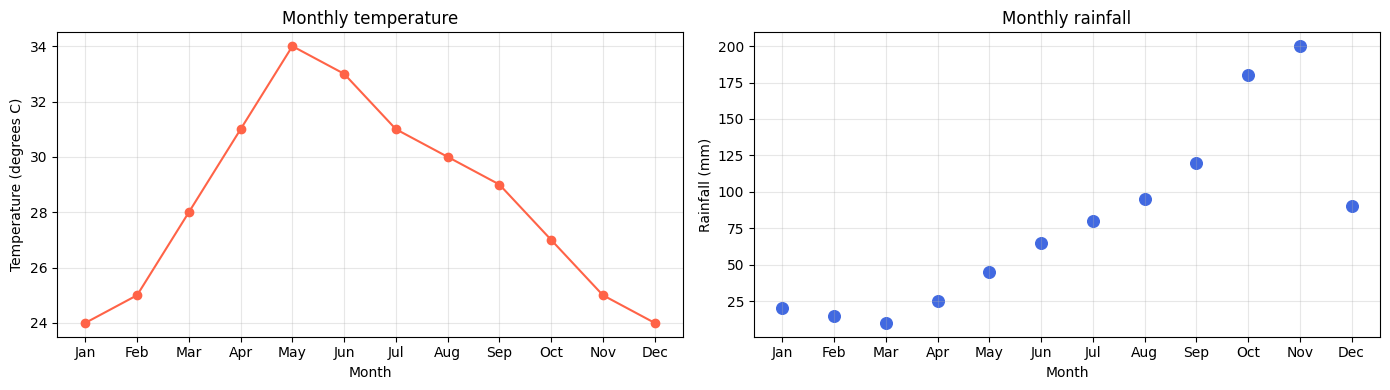

In [ ]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
temperature = [24, 25, 28, 31, 34, 33, 31, 30, 29, 27, 25, 24]
rainfall = [20, 15, 10, 25, 45, 65, 80, 95, 120, 180, 200, 90]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(months, temperature, marker="o", color="tomato")
axes[0].set_title("Monthly temperature")
axes[0].set_ylabel("Temperature (degrees C)")
axes[1].scatter(months, rainfall, color="royalblue", s=70)
axes[1].set_title("Monthly rainfall")
axes[1].set_ylabel("Rainfall (mm)")
for ax in axes:
    ax.set_xlabel("Month")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


13\. Question: How would you develop a Python program to calculate the frequency distribution of  
words in a text document?

In [ ]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd

file_path = Path("sample_text.txt")
if not file_path.exists():
    file_path.write_text(
        "Data science uses data to find patterns. Python makes data analysis "
        "simple. Data analysis helps companies make better decisions.",
        encoding="utf-8"
    )
text = file_path.read_text(encoding="utf-8")
words = re.findall(r"\b[a-z]+\b", text.lower())
frequency = Counter(words)
table = pd.DataFrame(frequency.most_common(), columns=["word", "frequency"])
print(table.to_string(index=False))


     word  frequency
     data          4
 analysis          2
  science          1
     uses          1
       to          1
     find          1
 patterns          1
   python          1
    makes          1
   simple          1
    helps          1
companies          1
     make          1
   better          1
decisions          1


14\. Question: Develop a code in python to find the frequency distribution of the ages of the customers  
who have made a purchase in the past month.

In [ ]:
import pandas as pd

purchase_data = pd.DataFrame({
    "customer_id": ["C101", "C102", "C103", "C101", "C104", "C105", "C106", "C107"],
    "age": [22, 25, 22, 22, 30, 25, 35, 40],
    "purchase_date": ["2026-09-02", "2026-09-05", "2026-09-08", "2026-09-12",
                      "2026-09-16", "2026-09-20", "2026-09-27", "2026-08-25"]
})
purchase_data["purchase_date"] = pd.to_datetime(purchase_data["purchase_date"])
analysis_date = pd.Timestamp("2026-10-01")
month_end = analysis_date.replace(day=1)
month_start = month_end - pd.DateOffset(months=1)
customers = purchase_data[
    (purchase_data["purchase_date"] >= month_start) &
    (purchase_data["purchase_date"] < month_end)
].drop_duplicates("customer_id")
age_frequency = customers["age"].value_counts().sort_index()
print("Age frequency among distinct purchasing customers:")
print(age_frequency.rename_axis("age").rename("customer_count"))


Age frequency among distinct purchasing customers:
age
22    2
25    2
30    1
35    1
Name: customer_count, dtype: int64


15\. Question: Develop a Python program to calculate the frequency distribution of likes among the  
posts?

In [ ]:
import pandas as pd

post_data = pd.DataFrame({
    "post_id": range(1, 13),
    "likes": [10, 20, 15, 10, 30, 20, 15, 10, 40, 30, 20, 50]
})
frequency = post_data["likes"].value_counts().sort_index()
print("Likes frequency distribution:")
print(frequency.rename_axis("likes").rename("number_of_posts"))


Likes frequency distribution:
likes
10    3
15    2
20    3
30    2
40    1
50    1
Name: number_of_posts, dtype: int64


16\. Question: Develop a Python program to calculate the frequency distribution of words in the  
customer reviews dataset?

In [ ]:
from collections import Counter
import re
import pandas as pd

reviews = pd.DataFrame({
    "review": [
        "The product is good and the delivery is fast.",
        "Good quality product with fast delivery!",
        "The product quality is excellent.",
        "Delivery was late but the product is good.",
        None
    ]
})
words = []
for review in reviews["review"].dropna():
    words.extend(re.findall(r"\b[a-z]+\b", str(review).lower()))
frequency = Counter(words)
print(pd.DataFrame(frequency.most_common(),
                   columns=["word", "frequency"]).to_string(index=False))


     word  frequency
      the          4
  product          4
       is          4
     good          3
 delivery          3
     fast          2
  quality          2
      and          1
     with          1
excellent          1
      was          1
     late          1
      but          1


17\. Question: Create a Python program that fulfills these requirements and helps your team gain  
insights from the customer feedback data.

Enter the number of top words to display: 10
     word  frequency
  product          4
 delivery          4
     good          4
excellent          3
  service          3
     fast          2
  quality          2
 customer          2
     slow          1
  helpful          1


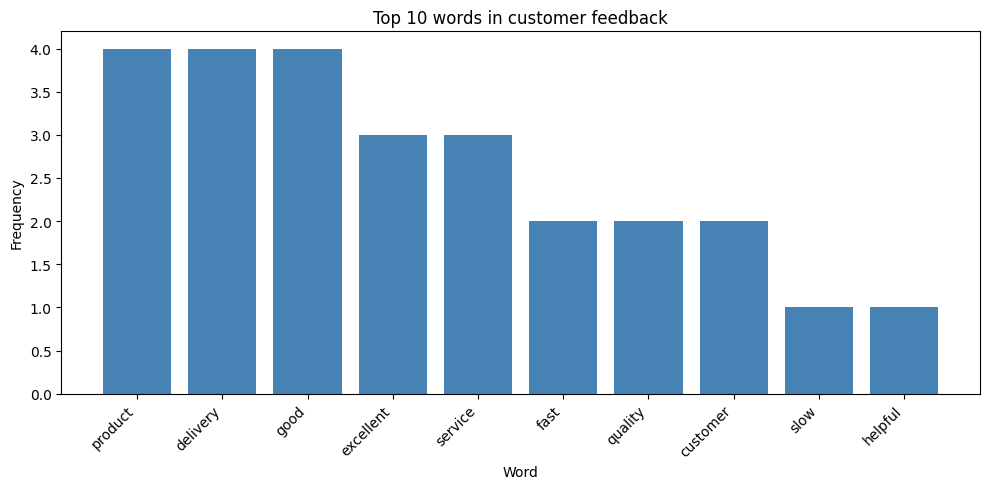

In [ ]:
from pathlib import Path
from collections import Counter
import string
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path("data.csv")
if not file_path.exists():
    pd.DataFrame({"feedback": [
        "The product is excellent and the delivery is fast.",
        "Good product quality and good customer service.",
        "The delivery is slow but the product is good.",
        "Excellent service and fast delivery.",
        "The product quality is excellent.",
        "Customer service is helpful and the delivery is good."
    ]}).to_csv(file_path, index=False)

feedback_data = pd.read_csv(file_path)
if "feedback" not in feedback_data.columns:
    raise ValueError("data.csv must contain a column named 'feedback'.")

stop_words = {
    "a", "an", "the", "and", "or", "but", "is", "are", "was", "were",
    "be", "been", "being", "to", "of", "in", "on", "at", "for", "with",
    "as", "by", "it", "its", "this", "that", "these", "those", "i", "we",
    "you", "he", "she", "they", "my", "our", "your", "their", "from",
    "has", "have", "had", "not", "so", "very", "do", "does", "did"
}
punctuation_to_spaces = str.maketrans({ch: " " for ch in string.punctuation})
word_frequency = Counter()
for feedback in feedback_data["feedback"].dropna():
    cleaned = str(feedback).lower().translate(punctuation_to_spaces)
    tokens = [word for word in cleaned.split()
              if word.isalpha() and word not in stop_words]
    word_frequency.update(tokens)

while True:
    try:
        n = int(input("Enter the number of top words to display: "))
        if n > 0:
            break
        print("Please enter a positive integer.")
    except ValueError:
        print("Please enter a valid integer.")

top_words = word_frequency.most_common(n)
if top_words:
    result = pd.DataFrame(top_words, columns=["word", "frequency"])
    print(result.to_string(index=False))
    plt.figure(figsize=(10, 5))
    plt.bar(result["word"], result["frequency"], color="steelblue")
    plt.title(f"Top {len(top_words)} words in customer feedback")
    plt.xlabel("Word")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No words remain after preprocessing.")


18\. Question:  
 Calculate the mean, median and standard deviation of age and %fat using Pandas.  
 Draw the boxplots for age and %fat.  
 Draw a scatter plot and a q-q plot based on these two variables

Illustrative data: 18 adults
          age  fat_percent
mean    47.50        23.38
median  47.50        23.85
std     16.02         6.10

Standard deviation uses ddof=1 (sample standard deviation).


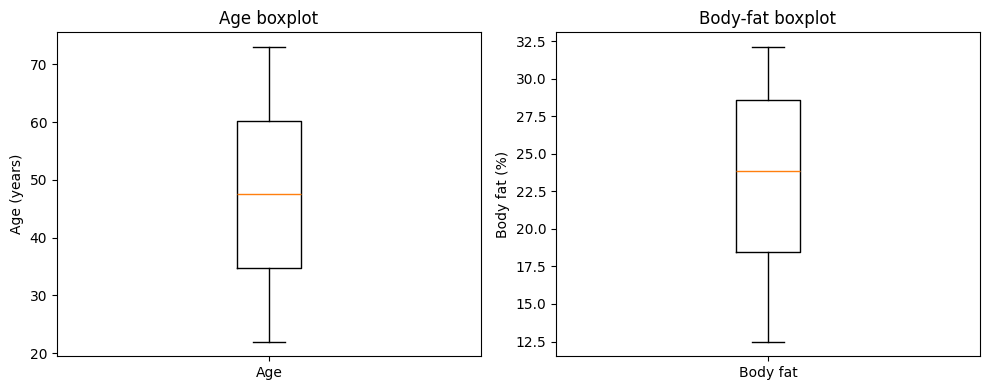

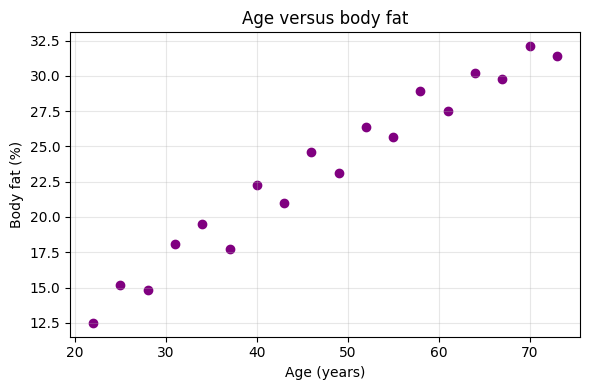

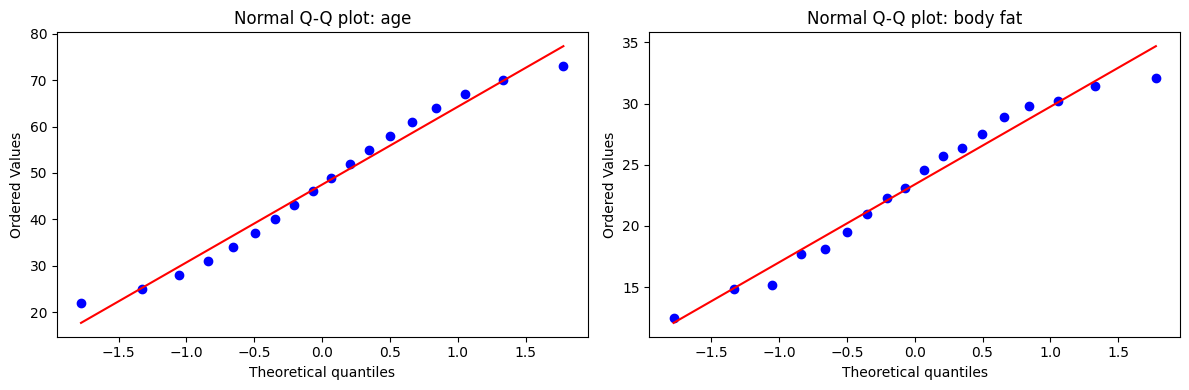

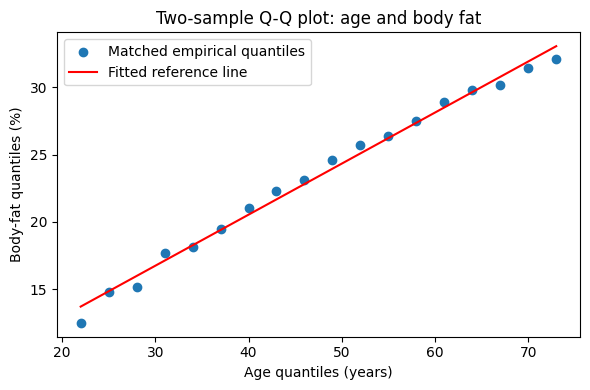

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

adult_data = pd.DataFrame({
    "age": [22, 25, 28, 31, 34, 37, 40, 43, 46,
            49, 52, 55, 58, 61, 64, 67, 70, 73],
    "fat_percent": [12.5, 15.2, 14.8, 18.1, 19.5, 17.7,
                    22.3, 21.0, 24.6, 23.1, 26.4, 25.7,
                    28.9, 27.5, 30.2, 29.8, 32.1, 31.4]
})
print("Illustrative data: 18 adults")
summary = adult_data.agg(["mean", "median", "std"])
print(summary.round(2))
print("\nStandard deviation uses ddof=1 (sample standard deviation).")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(adult_data["age"])
axes[0].set_title("Age boxplot")
axes[0].set_ylabel("Age (years)")
axes[0].set_xticks([1], ["Age"])
axes[1].boxplot(adult_data["fat_percent"])
axes[1].set_title("Body-fat boxplot")
axes[1].set_ylabel("Body fat (%)")
axes[1].set_xticks([1], ["Body fat"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(adult_data["age"], adult_data["fat_percent"], color="purple")
plt.title("Age versus body fat")
plt.xlabel("Age (years)")
plt.ylabel("Body fat (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(adult_data["age"], dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot: age")
stats.probplot(adult_data["fat_percent"], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot: body fat")
plt.tight_layout()
plt.show()

age_quantiles = np.sort(adult_data["age"].to_numpy())
fat_quantiles = np.sort(adult_data["fat_percent"].to_numpy())
slope, intercept = np.polyfit(age_quantiles, fat_quantiles, 1)
plt.figure(figsize=(6, 4))
plt.scatter(age_quantiles, fat_quantiles, label="Matched empirical quantiles")
plt.plot(age_quantiles, slope * age_quantiles + intercept,
         color="red", label="Fitted reference line")
plt.title("Two-sample Q-Q plot: age and body fat")
plt.xlabel("Age quantiles (years)")
plt.ylabel("Body-fat quantiles (%)")
plt.legend()
plt.tight_layout()
plt.show()


19\. Question:  
"What is the 95% confidence interval for the mean reduction in blood pressure for patients who  
received the new drug? Also, what is the 95% confidence interval for the mean reduction in blood  
pressure for patients who received the placebo?

In [ ]:
import numpy as np
from scipy import stats

drug_reduction = np.array([
    12, 15, 14, 10, 18, 16, 13, 17, 11, 15, 14, 19, 12,
    16, 13, 18, 15, 14, 17, 11, 16, 15, 13, 20, 14
], dtype=float)
placebo_reduction = np.array([
    3, 5, 2, 4, 6, 1, 3, 5, 4, 2, 7, 3, 4,
    5, 2, 6, 3, 4, 1, 5, 4, 2, 6, 3, 4
], dtype=float)

def mean_confidence_interval(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    if values.size < 2 or not np.isfinite(values).all():
        raise ValueError("Provide at least two finite reductions.")
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(values.size)
    critical_value = stats.t.ppf((1 + confidence) / 2, df=values.size - 1)
    margin = critical_value * standard_error
    return mean, mean - margin, mean + margin

print("Illustrative results only")
for label, values in [("Drug", drug_reduction), ("Placebo", placebo_reduction)]:
    mean, lower, upper = mean_confidence_interval(values)
    print(f"{label}: n={len(values)}, mean reduction={mean:.2f} mmHg")
    print(f"95% confidence interval: ({lower:.2f}, {upper:.2f}) mmHg\n")


Illustrative results only
Drug: n=25, mean reduction=14.72 mmHg
95% confidence interval: (13.66, 15.78) mmHg

Placebo: n=25, mean reduction=3.76 mmHg
95% confidence interval: (3.09, 4.43) mmHg



20\. Question:  
"Based on the data collected from the A/B test, is there a statistically significant difference in the  
mean conversion rates between website design A and website design B?"

In [ ]:
import numpy as np
from scipy import stats

design_a = np.array([1] * 120 + [0] * 880)
design_b = np.array([1] * 160 + [0] * 840)
alpha = 0.05

for values in [design_a, design_b]:
    if values.size == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("Each group must contain binary visitor outcomes.")

n_a, n_b = len(design_a), len(design_b)
success_a, success_b = design_a.sum(), design_b.sum()
rate_a, rate_b = design_a.mean(), design_b.mean()
pooled_rate = (success_a + success_b) / (n_a + n_b)
expected_counts = [n_a * pooled_rate, n_a * (1 - pooled_rate),
                   n_b * pooled_rate, n_b * (1 - pooled_rate)]
if min(expected_counts) < 5:
    raise ValueError("Expected counts are too small for this z-test; use an exact test.")

standard_error = np.sqrt(pooled_rate * (1 - pooled_rate) * (1 / n_a + 1 / n_b))
z_statistic = (rate_b - rate_a) / standard_error
p_value = 2 * stats.norm.sf(abs(z_statistic))
print("Illustrative A/B test results")
print(f"Design A: {success_a}/{n_a} conversions ({rate_a:.2%})")
print(f"Design B: {success_b}/{n_b} conversions ({rate_b:.2%})")
print(f"Difference B - A: {(rate_b - rate_a) * 100:.2f} percentage points")
print(f"z-statistic: {z_statistic:.4f}")
print(f"Two-sided p-value: {p_value:.6f}")
if p_value < alpha:
    print("Reject H0: a statistically significant difference is detected at alpha=0.05.")
else:
    print("Fail to reject H0: insufficient evidence of a difference at alpha=0.05.")


Illustrative A/B test results
Design A: 120/1000 conversions (12.00%)
Design B: 160/1000 conversions (16.00%)
Difference B - A: 4.00 percentage points
z-statistic: 2.5777
Two-sided p-value: 0.009946
Reject H0: a statistically significant difference is detected at alpha=0.05.
